
## Parte A — Arquitectura AWS

```mermaid
flowchart TD
    A[App móvil del conductor] --> B[Amazon API Gateway]
    B --> C[AWS Lambda]
    C --> D[(Amazon DynamoDB)]
    C --> E[(Amazon S3)]
    C --> F[(Amazon RDS PostgreSQL)]
    E --> G[Datos históricos por fecha]
    F --> H[Datos operativos relacionales]
```


In [1]:

# Lambda 1 — Verificar estado de una entrega

def lambda_verificar_entrega(event, context=None):
    delivery_id = event.get("delivery_id")
    status = str(event.get("status", "")).strip().lower()

    if not delivery_id:
        return {
            "statusCode": 400,
            "message": "Falta delivery_id"
        }

    completada = status in ("completed", "delivered")

    return {
        "statusCode": 200,
        "delivery_id": delivery_id,
        "entrega_completada": completada,
        "estado": status
    }


# Prueba local con datos simulados
evento_prueba = {
    "delivery_id": 1001,
    "status": "delivered"
}

resultado = lambda_verificar_entrega(evento_prueba)
print(resultado)


{'statusCode': 200, 'delivery_id': 1001, 'entrega_completada': True, 'estado': 'delivered'}


In [3]:

# Lambda 2 — Calcular tiempo estimado de llegada (ETA)

def lambda_calcular_eta(event, context=None):
    delivery_id = event.get("delivery_id")
    distancia_km = event.get("distancia_restante_km")
    velocidad_kmh = event.get("velocidad_promedio_kmh")

    if not delivery_id:
        return {
            "statusCode": 400,
            "message": "Falta delivery_id"
        }

    if not isinstance(distancia_km, (int, float)) or distancia_km < 0:
        return {
            "statusCode": 400,
            "message": "Distancia invalida"
        }

    if not isinstance(velocidad_kmh, (int, float)) or velocidad_kmh <= 0:
        return {
            "statusCode": 400,
            "message": "Velocidad invalida"
        }

    eta_minutos = round((distancia_km / velocidad_kmh) * 60, 2)

    return {
        "statusCode": 200,
        "delivery_id": delivery_id,
        "eta_minutos": eta_minutos
    }


# Prueba con valores simulados
evento_eta = {
    "delivery_id": 1001,
    "distancia_restante_km": 15,
    "velocidad_promedio_kmh": 45
}

resultado_eta = lambda_calcular_eta(evento_eta)
print(resultado_eta)


{'statusCode': 200, 'delivery_id': 1001, 'eta_minutos': 20.0}


In [4]:

# Lambda 3 — Detectar desvíos de ruta

def lambda_alerta_desvio(event, context=None):
    delivery_id = event.get("delivery_id")
    distancia_desvio_km = event.get("distancia_desvio_km")
    limite_km = event.get("limite_permitido_km", 2)

    if not delivery_id:
        return {
            "statusCode": 400,
            "message": "Falta delivery_id"
        }

    if (
        not isinstance(distancia_desvio_km, (int, float))
        or distancia_desvio_km < 0
        or not isinstance(limite_km, (int, float))
        or limite_km < 0
    ):
        return {
            "statusCode": 400,
            "message": "Distancia o limite invalido"
        }

    hay_desvio = distancia_desvio_km > limite_km

    return {
        "statusCode": 200,
        "delivery_id": delivery_id,
        "alerta_desvio": hay_desvio,
        "distancia_desvio_km": distancia_desvio_km,
        "limite_permitido_km": limite_km,
        "mensaje": (
            "ALERTA: vehiculo fuera de ruta"
            if hay_desvio
            else "Vehiculo dentro de la ruta permitida"
        )
    }


# Prueba local con valores simulados
evento_desvio = {
    "delivery_id": 1001,
    "distancia_desvio_km": 3.5,
    "limite_permitido_km": 2
}

resultado_desvio = lambda_alerta_desvio(evento_desvio)
print(resultado_desvio)


{'statusCode': 200, 'delivery_id': 1001, 'alerta_desvio': True, 'distancia_desvio_km': 3.5, 'limite_permitido_km': 2, 'mensaje': 'ALERTA: vehiculo fuera de ruta'}



## Parte C — Migración de datos y almacenamiento en AWS

### 1. Migración de PostgreSQL local a Amazon RDS

FleetLogix utiliza PostgreSQL como base de datos relacional de origen. Se propone migrarla a Amazon RDS for PostgreSQL para disponer de una base administrada en la nube.

La base de datos actual contiene:

| Tabla | Registros |
|---|---:|
| vehicles | 200 |
| drivers | 400 |
| routes | 50 |
| trips | 100.000 |
| deliveries | 400.000 |
| maintenance | 5.000 |
| **Total** | **505.650** |

#### Etapas de migración

1. Crear una instancia de Amazon RDS for PostgreSQL.
2. Configurar acceso privado, credenciales y permisos de seguridad.
3. Generar un respaldo de PostgreSQL local utilizando `pg_dump`.
4. Restaurar los datos en Amazon RDS mediante `pg_restore`.
5. Verificar tablas, claves, relaciones y cantidad de registros.
6. Ejecutar pruebas de conexión y consultas SQL.
7. Actualizar las conexiones de las aplicaciones para utilizar RDS.

La migración se presenta como una propuesta conceptual. No se realizó un despliegue real en AWS.

### 2. DynamoDB para el estado actual de las entregas

Se propone utilizar Amazon DynamoDB para almacenar y consultar rápidamente el estado más reciente de cada entrega.

**Tabla propuesta:** `FleetLogix_DeliveryStatus`

**Clave primaria:** `delivery_id`

Atributos propuestos:

- `delivery_id`: identificador de la entrega.
- `status`: estado actual.
- `driver_id`: conductor asignado.
- `vehicle_id`: vehículo utilizado.
- `last_update`: fecha y hora de actualización.
- `eta_minutes`: tiempo estimado de llegada.
- `route_deviation_alert`: indicador de desvío.

Las funciones AWS Lambda actualizarían esta información cuando se reciban eventos desde API Gateway.

### 3. Amazon S3 para datos históricos

Amazon S3 almacenaría los eventos históricos de las entregas en archivos JSON, organizados mediante particiones por fecha.

Ejemplo de estructura:

    fleetlogix-historical/
      deliveries/
        year=2026/
          month=11/
            day=18/
              events.json

Este almacenamiento facilitaría futuras consultas históricas, auditorías y procesos analíticos.

### 4. Backups automáticos y recuperación

Para proteger la información de FleetLogix se propone:

- **Amazon RDS:** habilitar backups automáticos con una retención inicial de 7 días.
- **Recuperación PITR:** permitir restaurar la base a un punto en el tiempo dentro del período disponible.
- **Amazon DynamoDB:** activar Point-in-Time Recovery para recuperar estados anteriores.
- **Amazon S3:** habilitar versionado y cifrado para proteger los archivos históricos.
- **AWS IAM:** limitar los permisos de acceso según cada servicio.
- **Pruebas de recuperación:** comprobar periódicamente que los respaldos puedan restaurarse correctamente.

### 5. Alcance de la solución

La arquitectura AWS es una propuesta de diseño. Las tres funciones Lambda fueron ejecutadas y verificadas localmente con eventos simulados.

No se desplegaron servicios reales de AWS ni se ejecutó la migración de PostgreSQL a RDS.


In [5]:

# Pruebas adicionales de las tres funciones Lambda

pruebas = [
    ("Entrega completada",
     lambda_verificar_entrega({"delivery_id": 1001, "status": "delivered"})["entrega_completada"] == True),

    ("Entrega pendiente",
     lambda_verificar_entrega({"delivery_id": 1002, "status": "pending"})["entrega_completada"] == False),

    ("Entrega sin identificador",
     lambda_verificar_entrega({"status": "delivered"})["statusCode"] == 400),

    ("ETA de 20 minutos",
     lambda_calcular_eta({"delivery_id": 1001, "distancia_restante_km": 15, "velocidad_promedio_kmh": 45})["eta_minutos"] == 20.0),

    ("Velocidad inválida",
     lambda_calcular_eta({"delivery_id": 1001, "distancia_restante_km": 15, "velocidad_promedio_kmh": 0})["statusCode"] == 400),

    ("Desvío detectado",
     lambda_alerta_desvio({"delivery_id": 1001, "distancia_desvio_km": 3.5})["alerta_desvio"] == True),

    ("Vehículo dentro de ruta",
     lambda_alerta_desvio({"delivery_id": 1002, "distancia_desvio_km": 1})["alerta_desvio"] == False)
]

for nombre, resultado in pruebas:
    print(f"{'OK' if resultado else 'ERROR'} - {nombre}")

print(f"\nPruebas superadas: {sum(resultado for _, resultado in pruebas)}/{len(pruebas)}")


OK - Entrega completada
OK - Entrega pendiente
OK - Entrega sin identificador
OK - ETA de 20 minutos
OK - Velocidad inválida
OK - Desvío detectado
OK - Vehículo dentro de ruta

Pruebas superadas: 7/7


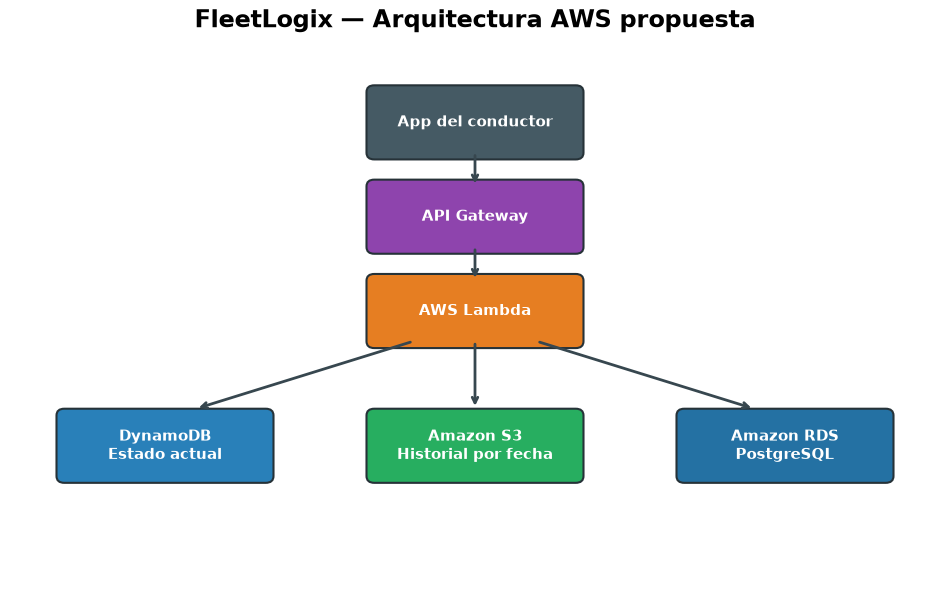

In [6]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(12, 7))
ax.set_xlim(0, 12)
ax.set_ylim(0, 8)
ax.axis("off")

def caja(x, y, texto, color):
    rect = FancyBboxPatch(
        (x - 1.3, y - 0.45), 2.6, 0.9,
        boxstyle="round,pad=0.1",
        facecolor=color, edgecolor="#263238", linewidth=1.5
    )
    ax.add_patch(rect)
    ax.text(x, y, texto, ha="center", va="center",
            fontsize=11, fontweight="bold", color="white")

def flecha(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", lw=2,
                                color="#37474F"))

caja(6, 7, "App del conductor", "#455A64")
caja(6, 5.6, "API Gateway", "#8E44AD")
caja(6, 4.2, "AWS Lambda", "#E67E22")

caja(2, 2.2, "DynamoDB\nEstado actual", "#2980B9")
caja(6, 2.2, "Amazon S3\nHistorial por fecha", "#27AE60")
caja(10, 2.2, "Amazon RDS\nPostgreSQL", "#2471A3")

flecha(6, 6.55, 6, 6.05)
flecha(6, 5.15, 6, 4.65)
flecha(5.2, 3.75, 2.4, 2.75)
flecha(6, 3.75, 6, 2.75)
flecha(6.8, 3.75, 9.6, 2.75)

ax.set_title("FleetLogix — Arquitectura AWS propuesta",
             fontsize=17, fontweight="bold", pad=20)

plt.savefig("fleetlogix_aws_architecture.png",
            dpi=180, bbox_inches="tight")
plt.show()
